# Simulation of the Hospital-Residents Problem with Biased Preferences

In [1]:
import sys
from pathlib import Path

project_root = Path.cwd().resolve().parent
sys.path.append(str(project_root / "src"))

In [2]:
from collections import defaultdict
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from simplematching.biased import generate_biased_HR
from simplematching.utils import normalize

In [3]:
def plot_rank_distribution(resident_prefs, max_rank=None, m_hospitals=None, ax=None):
    """
    Plot the distribution of ranks of each hospital.
    """
    ax_orig = ax

    num_hospitals = len(resident_prefs[0])
    if max_rank is None:
        max_rank = num_hospitals

    counts = defaultdict(lambda: [0] * num_hospitals)
    if m_hospitals is None:
        for prefs in resident_prefs:
            for rank, hospital in enumerate(prefs):
                counts[hospital][rank] += 1
    else:
        for hospital, residensts in enumerate(m_hospitals):
            for resident in residensts:
                prefs = resident_prefs[resident]
                rank = prefs.index(hospital)
                counts[hospital][rank] += 1

    df = pd.DataFrame(counts).T
    df.sort_index(inplace=True)
    df.columns = [f"{i+1}th" for i in range(num_hospitals)]
    if max_rank < num_hospitals:
        df[f">{max_rank}th"] = df.iloc[:, max_rank:].sum(axis=1)
        df.drop(columns=[f"{i+1}th" for i in range(max_rank, num_hospitals)], errors="ignore", inplace=True)

    bottom = pd.Series([0] * len(df), index=df.index)
    colors = plt.cm.tab20.colors

    if ax_orig is None:
        fig, ax = plt.subplots(figsize=(8, 5))

    for i, col in enumerate(df.columns):
        ax.bar(df.index, df[col], bottom=bottom, label=col, color=colors[i % len(colors)])
        bottom += df[col]

    if ax_orig is None:
        ax.set_xlabel("Hospital")
        ax.set_ylabel("Count of Residents")
        if m_hospitals is None:
            ax.set_title("Preference Rank Distribution of Hospitals (for all residents)")
        else:
            ax.set_title("Preference Rank Distribution of Hospitals (for matched residents)")
        ax.legend(title="Rank", bbox_to_anchor=(1.05, 1), loc="upper left", fontsize=8)
        plt.tight_layout()
        plt.show()

In [4]:
def plot_resident_preference_distribution(m_residents: list[int], resident_prefs: list[list[int]]):
    """
    Plot the distribution of residents' preference rankings for their matched hospitals.
    """

    n_residents = len(m_residents)
    n_hospitals = len(resident_prefs[0])

    data = [prefs.index(hospital) + 1 for hospital, prefs in zip(m_residents, resident_prefs)]
    counts = Counter(data)
    ranks = list(range(1, n_hospitals + 1))
    freq = [counts.get(i, 0) for i in ranks]
    cum_freq = np.cumsum(list(freq))

    fig, ax1 = plt.subplots(figsize=(8, 5))

    # Bar plot
    ax1.bar(ranks, freq)
    ax1.set_xlabel("Preference Ranking of Matched Hospital")
    ax1.set_ylabel("Number of Residents")
    ax1.set_xticks(ranks)

    # Line chart
    ax2 = ax1.twinx()
    ax2.plot(ranks, cum_freq, color='orange', marker='o', linewidth=2, label='Cumulative Frequency')
    ax2.set_ylabel("Cumulative Frequency")
    ax2.set_ylim(0, len(m_residents) * 1.1)

    plt.title("Distribution of Residents' Preference Rankings for Matched Hospitals")
    plt.tight_layout()
    plt.show()

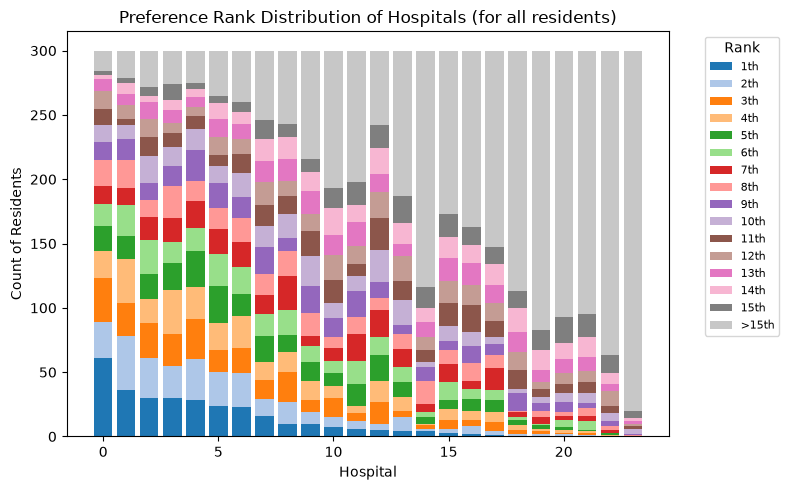

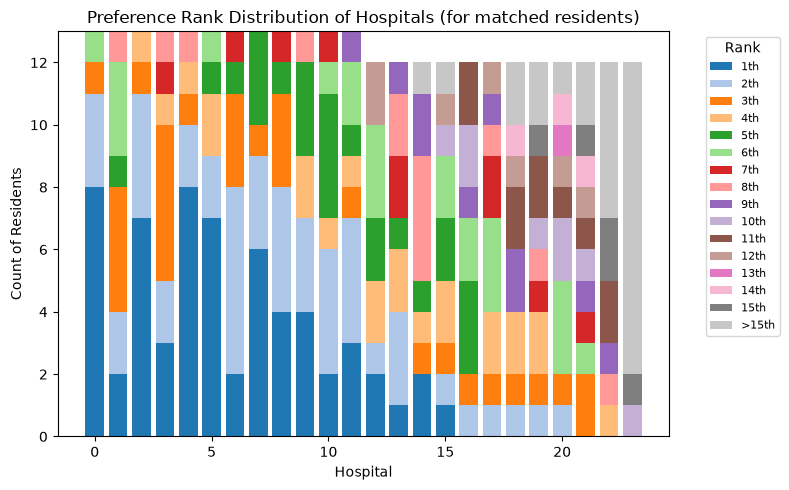

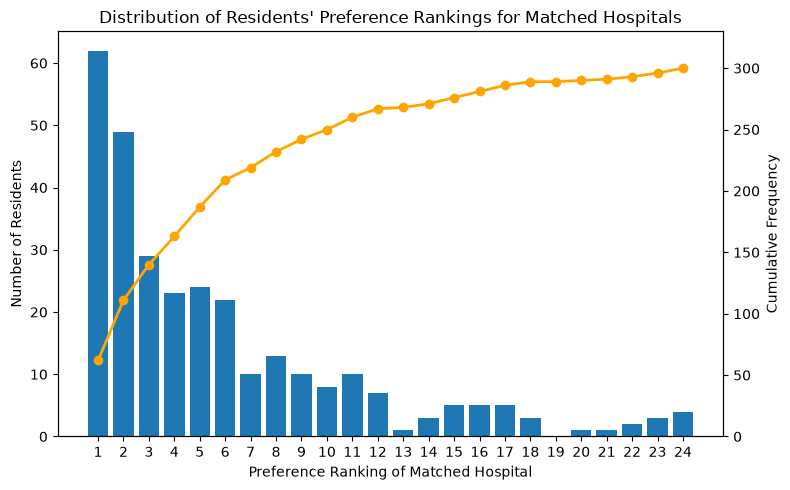

In [5]:
seed = 42
rng = np.random.default_rng(seed)

num_residents = 300
num_hospitals = 24

hr = generate_biased_HR(
    num_residents=num_residents,
    num_hospitals=num_hospitals,
    alpha_resident=0.5,
    alpha_hospital=0.5,
    list_length=num_hospitals,
    seed=seed,
)
hr.set_capacities(tight=True)
normalize(hr)

plot_rank_distribution(resident_prefs=hr.resident_prefs, max_rank=15)

m_residents, m_hospitals = hr.solve()

plot_rank_distribution(resident_prefs=hr.resident_prefs, max_rank=15, m_hospitals=m_hospitals)

plot_resident_preference_distribution(m_residents, hr.resident_prefs_completed())

## Effect of $\alpha_\mathrm{res}$

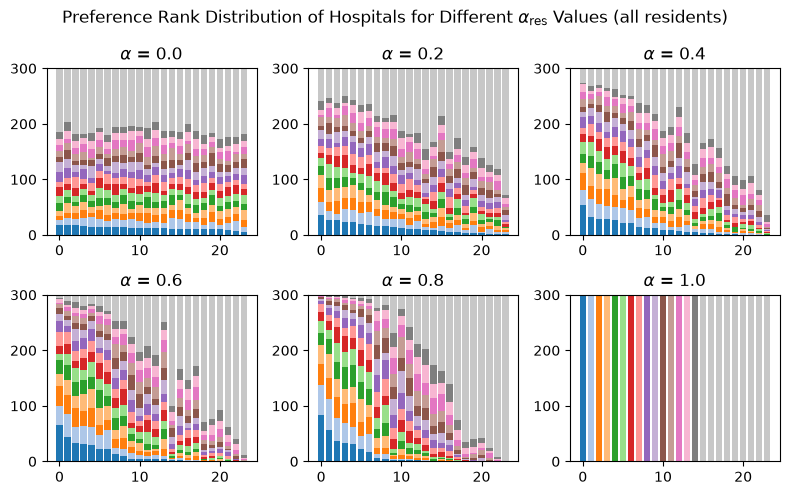

In [6]:
seed = 42

num_residents = 300
num_hospitals = 24
alphas = [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]

fig, axes = plt.subplots(2, 3, figsize=(8, 5))
axes = axes.flatten()

for ax, alpha in zip(axes, alphas):
    hr = generate_biased_HR(
        num_residents=num_residents,
        num_hospitals=num_hospitals,
        alpha_resident=alpha,
        alpha_hospital=0.5,
        list_length=num_hospitals,
        seed=seed,
    )
    normalize(hr)

    plot_rank_distribution(resident_prefs=hr.resident_prefs, max_rank=15, ax=ax)

    ax.set_title(f"$\\alpha$ = {alpha}")
    ax.set_ylim(0, num_residents)

fig.suptitle("Preference Rank Distribution of Hospitals for Different $\\alpha_\\mathrm{res}$ Values (all residents)")
plt.tight_layout()
plt.show()

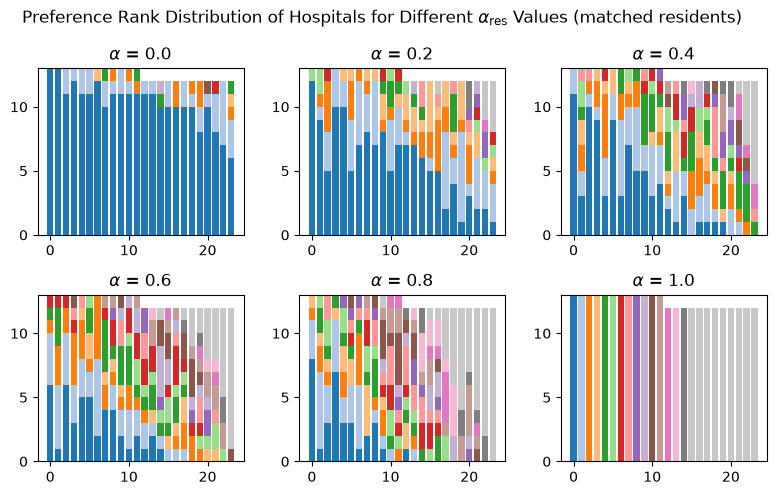

In [7]:
seed = 42

num_residents = 300
num_hospitals = 24
max_capacity = np.ceil(num_residents / num_hospitals).astype(int)
alphas = [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]

fig, axes = plt.subplots(2, 3, figsize=(8, 5))
axes = axes.flatten()

for ax, alpha in zip(axes, alphas):
    hr = generate_biased_HR(
        num_residents=num_residents,
        num_hospitals=num_hospitals,
        alpha_resident=alpha,
        alpha_hospital=0.5,
        list_length=num_hospitals,
        seed=seed,
    )
    hr.set_capacities(tight=True)
    normalize(hr)

    m_residents, m_hospitals = hr.solve()

    plot_rank_distribution(resident_prefs=hr.resident_prefs, max_rank=15, m_hospitals=m_hospitals, ax=ax)

    ax.set_title(f"$\\alpha$ = {alpha}")
    ax.set_ylim(0, max_capacity)

fig.suptitle("Preference Rank Distribution of Hospitals for Different $\\alpha_\\mathrm{res}$ Values (matched residents)")
plt.tight_layout()
plt.show()

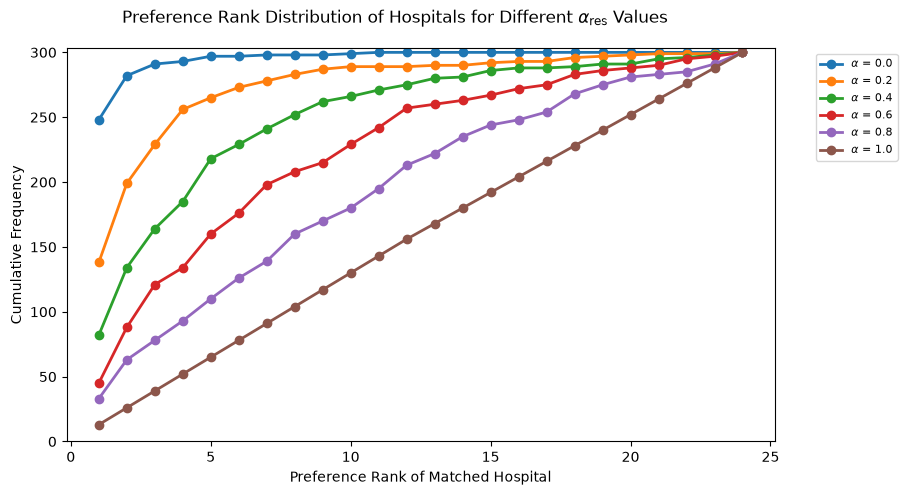

In [8]:
seed = 42

num_residents = 300
num_hospitals = 24
alphas = [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]

fig, ax = plt.subplots(figsize=(8, 5))

for alpha in alphas:
    hr = generate_biased_HR(
        num_residents=num_residents,
        num_hospitals=num_hospitals,
        alpha_resident=alpha,
        alpha_hospital=0.5,
        list_length=num_hospitals,
        seed=seed,
    )
    hr.set_capacities(tight=True)
    normalize(hr)

    m_residents, m_hospitals = hr.solve()

    data = [prefs.index(hospital) + 1 for hospital, prefs in zip(m_residents, hr.resident_prefs)]
    counts = Counter(data)
    ranks = list(range(1, hr.num_hospitals + 1))
    freq = [counts.get(i, 0) for i in ranks]
    cum_freq = np.cumsum(list(freq))

    # Line chart
    ax.plot(ranks, cum_freq, marker='o', linewidth=2, label=f'$\\alpha$ = {alpha}')

plt.xlabel("Preference Rank of Matched Hospital")
plt.ylabel("Cumulative Frequency")
plt.ylim(0, hr.num_residents * 1.01)

fig.suptitle("Preference Rank Distribution of Hospitals for Different $\\alpha_\\mathrm{res}$ Values")
plt.tight_layout()
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left", fontsize=8)
plt.show()

A smaller value of `alpha_resident` (i.e., a lower correlation among preference rankings) results in a higher proportion of residents being assigned to their higher-ranked (more preferred) hospitals.

## Effect of $\alpha_\mathrm{hos}$

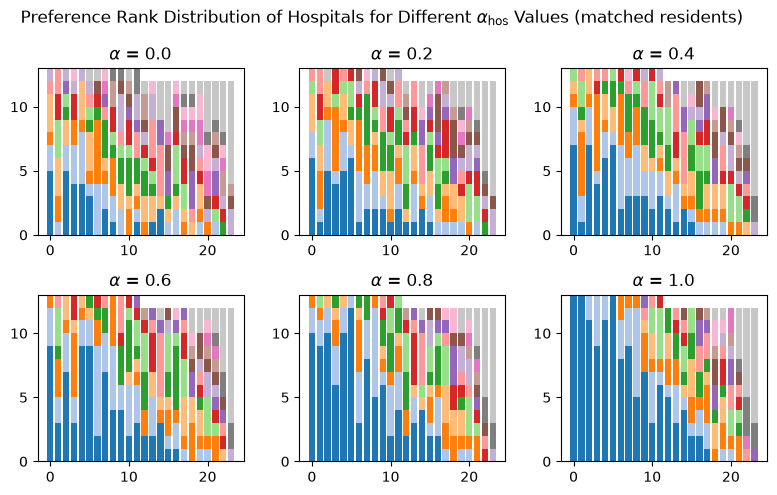

In [9]:
seed = 42

num_residents = 300
num_hospitals = 24
max_capacity = np.ceil(num_residents / num_hospitals).astype(int)
alphas = [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]

fig, axes = plt.subplots(2, 3, figsize=(8, 5))
axes = axes.flatten()

for ax, alpha in zip(axes, alphas):
    hr = generate_biased_HR(
        num_residents=num_residents,
        num_hospitals=num_hospitals,
        alpha_resident=0.5,
        alpha_hospital=alpha,
        list_length=num_hospitals,
        seed=seed,
    )
    hr.set_capacities(tight=True)
    normalize(hr)

    m_residents, m_hospitals = hr.solve()

    plot_rank_distribution(resident_prefs=hr.resident_prefs, max_rank=15, m_hospitals=m_hospitals, ax=ax)

    ax.set_title(f"$\\alpha$ = {alpha}")
    ax.set_ylim(0, max_capacity)

fig.suptitle("Preference Rank Distribution of Hospitals for Different $\\alpha_\\mathrm{hos}$ Values (matched residents)")
plt.tight_layout()
plt.show()

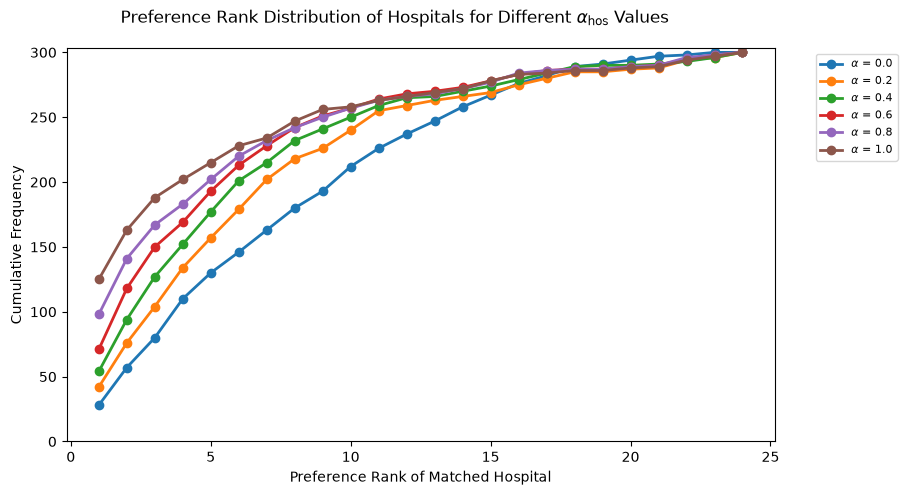

In [10]:
seed = 42

num_residents = 300
num_hospitals = 24
alphas = [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]

fig, ax = plt.subplots(figsize=(8, 5))

for alpha in alphas:
    hr = generate_biased_HR(
        num_residents=num_residents,
        num_hospitals=num_hospitals,
        alpha_resident=0.5,
        alpha_hospital=alpha,
        list_length=num_hospitals,
        seed=seed,
    )
    hr.set_capacities(tight=True)
    normalize(hr)

    m_residents, m_hospitals = hr.solve()

    data = [prefs.index(hospital) + 1 for hospital, prefs in zip(m_residents, hr.resident_prefs)]
    counts = Counter(data)
    ranks = list(range(1, hr.num_hospitals + 1))
    freq = [counts.get(i, 0) for i in ranks]
    cum_freq = np.cumsum(list(freq))

    # Line chart
    ax.plot(ranks, cum_freq, marker='o', linewidth=2, label=f'$\\alpha$ = {alpha}')

plt.xlabel("Preference Rank of Matched Hospital")
plt.ylabel("Cumulative Frequency")
plt.ylim(0, hr.num_residents * 1.01)

fig.suptitle("Preference Rank Distribution of Hospitals for Different $\\alpha_\\mathrm{hos}$ Values")
plt.tight_layout()
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left", fontsize=8)
plt.show()

As `alpha_hospital` increases over the range 0.0, 0.2, ..., 1.0, the preference rank improves.